# Gradient Boosting for Regression
### A walkthrough of `GradientBoostRegression.py` and `DecisionTreeGradientBoostRegression.py`

**Gradient boosting** builds a prediction as a sum of many small regression trees. It starts from a constant. Each new tree is fitted to the *errors* the current model still makes, and only a small fraction $\eta$ of that tree is added. With squared error, "the errors" are literally the residuals $y - F(x)$. More generally they are the negative gradient of the loss, which is why the method is called *gradient* boosting: it performs gradient descent in the space of functions.

This notebook derives the algorithm and runs the implementation in this folder at every step. By the end you should be able to:

1. derive the starting value $F_0 = \bar y$ and show that the negative gradient of the squared loss is the residual;
2. explain why each tree's leaves should hold the *mean residual* (a Newton step with a constant Hessian), and why shrinkage $\eta$ helps;
3. prove that training error never increases for $0 < \eta < 2$, and check it against the code;
4. explain line by line how `GradientBoostingRegressor` and its tree fit, predict, stage and score features;
5. tune `n_estimators`, `learning_rate` and `max_depth`, and see why stumps cannot represent feature interactions.

Prerequisites: the [Regression Tree walkthrough](../DecisionTreeRegression/DecisionTreeRegression_Walkthrough.ipynb) (variance reduction, mean leaves, bias–variance) and, for the boosting idea, the [AdaBoost walkthrough](../AdaBoost/AdaBoost_Walkthrough.ipynb).

**Pattern.** Each core topic follows **Concept → Math → Illustration → Your implementation → Check**. Cells titled *🔧 Fixed in the code* record bugs found while this notebook was being written and since corrected in the `.py` files. Cells titled *⚠️ Note on the implementation* describe design choices that remain.

**Series:** [Decision Tree](../DecisionTree/DecisionTree_Walkthrough.ipynb) · [Regression Tree](../DecisionTreeRegression/DecisionTreeRegression_Walkthrough.ipynb) · [Random Forest](../RandomForest/RandomForest_Walkthrough.ipynb) · [AdaBoost](../AdaBoost/AdaBoost_Walkthrough.ipynb) · **Gradient Boosting (regression)** · [Gradient Boosting (classification)](../GradientBoostClassification/GradientBoostClassification_Walkthrough.ipynb) · [XGBoost](../XGBoost/XGBoost_Walkthrough.ipynb)

**Notation.** $n$ samples, $m$ features, targets $y_i \in \mathbb{R}$. $F_t(x)$ is the model after $t$ trees, with $F_0$ the constant start. $f_t$ is the $t$-th tree, $\eta$ the learning rate, and $T$ the number of trees. $r_i^{(t)} = y_i - F_{t-1}(x_i)$ is the residual (pseudo-residual) used to fit tree $t$. $R_{\ell}$ and $v_\ell$ are a leaf's region and value.

## 1. Setup

In [1]:
# Setup: imports, reproducibility, plot style, and the import path to the repo modules
import sys, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

NB_DIR = Path.cwd()                       # Jupyter starts the kernel in the notebook's own folder
assert (NB_DIR / "GradientBoostRegression.py").exists(), "Open/run this notebook from inside the GradientBoostRegression/ folder"
if str(NB_DIR) not in sys.path:
    sys.path.insert(0, str(NB_DIR))       # makes the repo modules in this folder importable

SEED = 0
rng = np.random.default_rng(SEED)         # the notebook's own generator for all synthetic data; it is independent
                                          # of NumPy's global random state and of the models' private generators
np.set_printoptions(precision=4, suppress=True)

# One plot style shared by every walkthrough notebook in this repo
plt.rcParams.update({
    "figure.figsize": (7, 4.5), "figure.dpi": 100,
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.labelsize": 11, "legend.fontsize": 9, "legend.frameon": False,
})
CLASS_COLORS  = ["#1f77b4", "#d62728", "#2ca02c", "#9467bd"]   # class 0, 1, 2, 3 (points)
REGION_COLORS = ["#c6dbef", "#fcbba1", "#c7e9c0", "#dadaeb"]   # class 0, 1, 2, 3 (decision regions)

In [2]:
# Teaching helpers — Illustration only, not the repo implementation.
# Synthetic-data generators, a train/test split, a decision-region plotter, and read-only
# inspectors that walk the Node objects built by the repo code (they never modify a tree).

def make_xor(n, noise=0.0, rng=rng):
    """Points uniform on [-1, 1]^2; class 1 when x0*x1 < 0 (2nd and 4th quadrants). `noise` = label-flip rate."""
    X = rng.uniform(-1, 1, size=(n, 2))
    y = (X[:, 0] * X[:, 1] < 0).astype(float)
    flip = rng.random(n) < noise
    y[flip] = 1 - y[flip]
    return X, y

def make_moons(n, noise=0.2, rng=rng):
    """Two interleaving half-circles with Gaussian jitter (the classic 'moons' toy problem)."""
    n0 = n // 2; n1 = n - n0
    t0, t1 = rng.uniform(0, np.pi, n0), rng.uniform(0, np.pi, n1)
    X = np.r_[np.c_[np.cos(t0), np.sin(t0)], np.c_[1 - np.cos(t1), 0.5 - np.sin(t1)]]
    X = X + noise * rng.normal(size=(n, 2))
    return X, np.r_[np.zeros(n0), np.ones(n1)]

def make_blobs(n, centers, std=1.0, rng=rng):
    """Gaussian clusters; the label is the index of the cluster a point came from."""
    centers = np.asarray(centers, dtype=float)
    y = rng.integers(0, len(centers), size=n)
    X = centers[y] + std * rng.normal(size=(n, centers.shape[1]))
    return X, y.astype(float)

def noisy_sine(n, noise=0.3, rng=rng):
    """1-D regression toy problem: y = sin(x) + Gaussian noise, x uniform on [0, 2*pi]."""
    x = np.sort(rng.uniform(0, 2 * np.pi, n))
    return x.reshape(-1, 1), np.sin(x) + noise * rng.normal(size=n)

def train_test_split_np(X, y, test_frac=0.3, rng=rng):
    """Random train/test split with NumPy only."""
    idx = rng.permutation(len(X))
    n_test = int(round(test_frac * len(X)))
    te, tr = idx[:n_test], idx[n_test:]
    return X[tr], X[te], y[tr], y[te]

def iter_nodes(node):
    """Yield every node of a tree in pre-order (works with every Node class in this repo)."""
    if node is None:
        return
    yield node
    if node.value is None:                       # decision node: recurse into both children
        yield from iter_nodes(node.left)
        yield from iter_nodes(node.right)

def tree_depth(node):
    """Number of edges on the longest root-to-leaf path (a single leaf has depth 0)."""
    return 0 if node.value is not None else 1 + max(tree_depth(node.left), tree_depth(node.right))

def count_leaves(node):
    return sum(1 for nd in iter_nodes(node) if nd.value is not None)

def plot_decision_regions(predict_fn, X, y, ax=None, title="", grid_n=120, pad=0.4, legend=True):
    """Colour a grid by predict_fn's class label, then overlay the data points coloured by true class."""
    ax = ax or plt.gca()
    g0 = np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, grid_n)
    g1 = np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, grid_n)
    G0, G1 = np.meshgrid(g0, g1)
    Z = np.asarray(predict_fn(np.c_[G0.ravel(), G1.ravel()]), dtype=float).reshape(G0.shape)
    K = int(max(Z.max(), y.max())) + 1
    ax.contourf(G0, G1, Z, levels=np.arange(K + 1) - 0.5, cmap=ListedColormap(REGION_COLORS[:K]))
    for k in range(K):
        m = y == k
        ax.scatter(X[m, 0], X[m, 1], s=16, c=CLASS_COLORS[k], edgecolor="white", linewidth=0.4, label=f"class {k}")
    ax.set_title(title); ax.set_xlabel("$x_0$"); ax.set_ylabel("$x_1$")
    if legend:
        ax.legend(loc="upper right", frameon=True, framealpha=0.8)
    return ax

In [3]:
# The implementation under study: imported from this folder, never copied into the notebook
from GradientBoostRegression import GradientBoostingRegressor
from DecisionTreeGradientBoostRegression import DecisionTreeRegressor

print("GradientBoostingRegressor methods:", [k for k in vars(GradientBoostingRegressor) if not k.startswith("__")])
print("DecisionTreeRegressor methods:    ", [k for k in vars(DecisionTreeRegressor) if not k.startswith("__")])

# Illustration helper: which leaf (Node object) does each row reach? Used to group samples by leaf.
def leaf_of(x, node):
    while node.value is None:
        node = node.left if x[node.feature_index] <= node.threshold else node.right
    return node

GradientBoostingRegressor methods: ['fit', 'predict', 'get_staged_predictions', 'get_feature_importance', 'calculate_tree_importance']
DecisionTreeRegressor methods:     ['build_tree', 'get_best_split', 'variance_reduction', 'split', 'calculate_leaf_value', 'print_tree', 'fit', 'predict', 'make_prediction']


## 2. The problem: regression with squared error

We want $\hat f(x) \approx E[y \mid x]$, the minimiser of the squared-error risk $E[(y - \hat f(x))^2]$; the [Regression Tree notebook](../DecisionTreeRegression/DecisionTreeRegression_Walkthrough.ipynb#2.-The-problem:-regression-under-squared-error) derives this. The running example below mixes a smooth trend with an oscillation: $\mu(x) = \sin(2x) + 0.5x$ on $[0, 3]$, plus Gaussian noise with $\sigma = 0.2$. It is easy to see, and hard for a single small tree to capture.

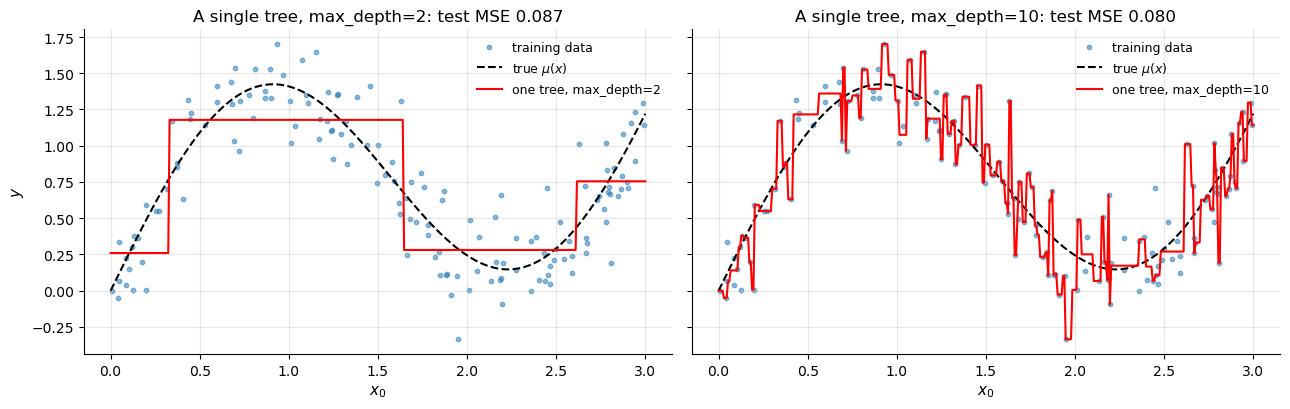

In [4]:
SIGMA = 0.2
mu = lambda x: np.sin(2 * x) + 0.5 * x
def make_curve(n):
    x = np.sort(rng.uniform(0, 3, n))
    return x.reshape(-1, 1), mu(x) + SIGMA * rng.normal(size=n)
X_tr, y_tr = make_curve(150)
X_te, y_te = make_curve(1000)
xg = np.linspace(0, 3, 400).reshape(-1, 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, depth in zip(axes, [2, 10]):
    t = DecisionTreeRegressor(max_depth=depth); t.fit(X_tr, y_tr)
    mse = np.mean((t.predict(X_te) - y_te) ** 2)
    ax.scatter(X_tr, y_tr, s=10, alpha=0.5, color=CLASS_COLORS[0], label="training data")
    ax.plot(xg, mu(xg), "k--", label="true $\\mu(x)$"); ax.plot(xg, t.predict(xg), "r", label=f"one tree, max_depth={depth}")
    ax.set(title=f"A single tree, max_depth={depth}: test MSE {mse:.3f}", xlabel="$x_0$"); ax.legend()
axes[0].set_ylabel("$y$"); plt.tight_layout(); plt.show()

A shallow tree is far too coarse (high bias), and a deep tree chases the noise (high variance). The irreducible error here is $\sigma^2 = 0.04$. Gradient boosting builds a *sum* of shallow trees: each is low-variance, and the sum is flexible.

## 3. Why gradient boosting fits this problem

**Additive models.** Gradient boosting fits $F_T(x) = F_0 + \eta \sum_{t=1}^T f_t(x)$, a sum of many shallow trees. A sum of step functions can approximate a smooth curve much better than any single step function of similar depth, and keeping each tree shallow keeps its variance low.

**Greedy, sequential, error-driven.** Like [AdaBoost](../AdaBoost/AdaBoost_Walkthrough.ipynb), trees are added one at a time, each to fix what is still wrong. Gradient boosting replaces AdaBoost's sample re-weighting with something more direct and more general: it fits each tree to the **negative gradient of the loss**. For squared error that is the residual, but the same recipe works for any differentiable loss: log-loss for [classification](../GradientBoostClassification/GradientBoostClassification_Walkthrough.ipynb), absolute or Huber loss for robust regression, and so on.

**Compared with forests.** A [random forest](../RandomForest/RandomForest_Walkthrough.ipynb) averages independent deep trees to cut variance. Gradient boosting adds dependent shallow trees to cut bias, and uses shrinkage and the number of trees to control the variance it gradually introduces.

## 4. Core concepts, theory and math

### 4.1 Start from the best constant

**Math.** Before any tree, the model is a constant $F_0 = c$. The squared loss $\sum_i (y_i - c)^2$ is minimised where its derivative $-2\sum_i(y_i - c)$ vanishes, at $c = \bar y$, the mean target (Eq. 1 of the regression-tree notebook).

$$
F_0 = \arg\min_c \sum_{i=1}^n (y_i - c)^2 = \bar y . \tag{1}
$$

**Your implementation and check.** `fit` stores this as `init_prediction_`.

In [5]:
gb0 = GradientBoostingRegressor(n_estimators=0); gb0.fit(X_tr, y_tr)
print(f"init_prediction_ = {gb0.init_prediction_:.6f},  mean(y) = {y_tr.mean():.6f}")
assert np.isclose(gb0.init_prediction_, y_tr.mean()) and np.allclose(gb0.predict(X_te), y_tr.mean())
print("✓ F_0 is the training mean, and a model with zero trees predicts it everywhere")

init_prediction_ = 0.698758,  mean(y) = 0.698758
✓ F_0 is the training mean, and a model with zero trees predicts it everywhere


### 4.2 The negative gradient of the squared loss is the residual

**Concept.** Think of the model's predictions at the $n$ training points, $\mathbf F = (F(x_1), \dots, F(x_n))$, as $n$ free numbers. To reduce the loss, move them in the direction of steepest descent, the **negative gradient** of the loss with respect to these numbers.

**Math.** With $L(\mathbf F) = \sum_i \tfrac12 (y_i - F(x_i))^2$,

$$
-\frac{\partial L}{\partial F(x_i)} = -\tfrac12 \cdot 2\,(y_i - F(x_i))\cdot(-1) = y_i - F(x_i) = r_i . \tag{2}
$$

So the steepest-descent direction at the training points is exactly the vector of **residuals**. (Without the factor $\tfrac12$ the gradient is $2r_i$; the scale is absorbed by the step size, see §4.3.) A gradient step on the raw numbers would only change the predictions *at the training points*. Gradient boosting instead fits a **regression tree** $f_t$ to the residuals. The tree is a function defined everywhere that approximates the descent direction, so the step also generalises to new inputs $x$.

**Illustration and check.** A finite-difference derivative of $L$ with respect to one prediction, compared with the residual.

In [6]:
# Illustration only — finite-difference check of Eq. (2) at a few training points
F = np.full(len(y_tr), y_tr.mean())                        # current predictions F_0
L = lambda F_: 0.5 * np.sum((y_tr - F_) ** 2)
for i in [0, 50, 120]:
    h = 1e-6; Fp = F.copy(); Fp[i] += h
    print(f"i = {i:>3}: -dL/dF_i ≈ {-(L(Fp) - L(F)) / h:+.5f}   residual y_i - F_i = {y_tr[i] - F[i]:+.5f}")
    assert np.isclose(-(L(Fp) - L(F)) / h, y_tr[i] - F[i], atol=1e-4)

i =   0: -dL/dF_i ≈ -0.70000   residual y_i - F_i = -0.70000
i =  50: -dL/dF_i ≈ +0.48321   residual y_i - F_i = +0.48321
i = 120: -dL/dF_i ≈ -0.35792   residual y_i - F_i = -0.35792


### 4.3 One boosting round: fit a tree to the residuals, then take a damped step

**Concept.** Each round:
1. computes the residuals $r_i = y_i - F_{t-1}(x_i)$;
2. fits a regression tree $f_t$ to the pairs $(x_i, r_i)$ by variance reduction, which partitions the inputs into regions where the residuals are similar;
3. sets each leaf to the **mean residual** of its samples;
4. updates $F_t = F_{t-1} + \eta\, f_t$.

**Math: why the mean residual is the right leaf value.** Given the regions $R_\ell$ chosen by the tree, the best constant to add inside each region solves a one-dimensional "line search":

$$
v_\ell^* = \arg\min_{v} \sum_{i:\, x_i \in R_\ell} \tfrac12\big(y_i - (F_{t-1}(x_i) + v)\big)^2 = \arg\min_v \sum_{i \in R_\ell} \tfrac12 (r_i - v)^2 = \frac{1}{|R_\ell|}\sum_{i\in R_\ell} r_i . \tag{3}
$$

Equivalently, a **Newton step**. The gradient of the leaf's loss at $v = 0$ is $g = -\sum r_i$ and the Hessian is $h = \sum 1 = |R_\ell|$, so the step $-g/h = \bar r_\ell$. Because the squared loss has a **constant** Hessian, the Newton step is just the mean. The classification notebook will need a genuine Newton step, where the Hessian varies from sample to sample.

**Math: shrinkage.** Adding the full tree ($\eta = 1$) would make the training residuals inside each leaf average to zero immediately, which overfits the noise in that leaf. With $\eta < 1$, each tree corrects only part of the error. The remaining error is redistributed among many later trees, which average out each other's noise. This is the main regulariser of gradient boosting: empirically, a smaller $\eta$ with more trees almost always generalises better (Friedman, 2001).

**Your implementation.** We fit one round by hand with the repo's `DecisionTreeRegressor`, then compare with the first tree inside `GradientBoostingRegressor`.

In [7]:
eta = 0.5
r1 = y_tr - y_tr.mean()                                         # residuals after F_0
tree1 = DecisionTreeRegressor(max_depth=2); tree1.fit(X_tr, r1)
tree1.print_tree()

gb1 = GradientBoostingRegressor(n_estimators=1, max_depth=2, learning_rate=eta); gb1.fit(X_tr, y_tr)
print("\nsame tree inside GradientBoostingRegressor:", np.allclose(gb1.trees[0].predict(X_te), tree1.predict(X_te)))

X_0 <= 1.644354752980065 ? 0.0669
    left:X_0 <= 0.3306418692767021 ? 0.1508
        left:-0.4392
        right:0.4796
    right:X_0 <= 2.610186481584419 ? 0.0511
        left:-0.4179
        right:0.0557

same tree inside GradientBoostingRegressor: True


In [8]:
# Check — Eq. (3): every leaf holds the mean residual of the training samples that reach it,
# and the one-round model is F_0 + η·f_1
groups = {}
for x_i, r_i in zip(X_tr, r1):
    groups.setdefault(id(leaf_of(x_i, tree1.root)), []).append(r_i)
for nd in iter_nodes(tree1.root):
    if nd.value is not None:
        assert np.isclose(nd.value, np.mean(groups[id(nd)]))
        print(f"leaf value {nd.value:+.4f} = mean of {len(groups[id(nd)]):>3} residuals")
assert np.allclose(gb1.predict(X_te), y_tr.mean() + eta * tree1.predict(X_te))
print("✓ leaves are mean residuals (Eq. 3) and predict() = F_0 + η·f_1(x)")

leaf value -0.4392 = mean of  17 residuals
leaf value +0.4796 = mean of  56 residuals
leaf value -0.4179 = mean of  50 residuals
leaf value +0.0557 = mean of  27 residuals
✓ leaves are mean residuals (Eq. 3) and predict() = F_0 + η·f_1(x)


The first tree inside the model is exactly the tree we fit by hand to $y - \bar y$. Each of its leaves holds the mean residual of its region, and the model's prediction is $F_0 + \eta f_1(x)$.

### 4.4 Training error can only go down (for $0 < \eta < 2$)

**Math.** Fix one round and one leaf $\ell$ with residuals $r_i$ and mean $\bar r$. After the update, the new residuals in that leaf are $r_i - \eta \bar r$. Using $\sum_{i\in\ell}(r_i - \bar r) = 0$:

$$
\sum_{i\in\ell}(r_i - \eta\bar r)^2 = \sum_{i\in\ell}\big((r_i - \bar r) + (1-\eta)\bar r\big)^2 = \sum_{i\in\ell}(r_i-\bar r)^2 + |\ell|\,(1-\eta)^2\bar r^{\,2},
$$

while before the update $\sum_{i\in\ell} r_i^2 = \sum_{i\in\ell}(r_i - \bar r)^2 + |\ell|\,\bar r^{\,2}$. So the leaf's training SSE changes by $-|\ell|\,\bar r^{\,2}\,[1 - (1-\eta)^2] = -|\ell|\,\bar r^{\,2}\,\eta(2-\eta)$, which is $\le 0$ whenever $0 < \eta < 2$. Summing over leaves, **the training MSE never increases**. It decreases strictly unless every leaf's mean residual is zero. The decrease per round is largest at $\eta = 1$ and shrinks as $\eta \to 0$, which is the price of shrinkage. $\eta > 2$ would overshoot and diverge.

**Check.** `get_staged_predictions` returns the training predictions after every round; their MSE must be non-increasing. We also verify the exact per-round decrease formula.

In [9]:
gbm = GradientBoostingRegressor(n_estimators=60, max_depth=2, learning_rate=0.3); gbm.fit(X_tr, y_tr)
stages = [np.full(len(y_tr), gbm.init_prediction_)] + gbm.get_staged_predictions(X_tr)
sse = np.array([np.sum((y_tr - s) ** 2) for s in stages])
assert np.all(np.diff(sse) <= 1e-9)
# exact decrease: Σ_leaves |ℓ| r̄_ℓ² η(2-η), with r̄ from the residuals before each round
for t in [0, 10, 40]:
    r = y_tr - stages[t]; tr = gbm.trees[t]; leaves = {}
    for x_i, r_i in zip(X_tr, r):
        leaves.setdefault(id(leaf_of(x_i, tr.root)), []).append(r_i)
    predicted = sum(len(v) * np.mean(v) ** 2 for v in leaves.values()) * 0.3 * (2 - 0.3)
    assert np.isclose(sse[t] - sse[t + 1], predicted)
    print(f"round {t + 1:>2}: SSE {sse[t]:8.4f} -> {sse[t + 1]:8.4f}  (drop {sse[t] - sse[t + 1]:.5f} = formula {predicted:.5f})")
print(f"✓ training SSE is non-increasing over all {len(gbm.trees)} rounds, and each drop equals Σ|ℓ| r̄² η(2-η)")

round  1: SSE  34.9912 ->  22.2529  (drop 12.73829 = formula 12.73829)
round 11: SSE   5.5452 ->   5.4241  (drop 0.12111 = formula 0.12111)
round 41: SSE   3.2457 ->   3.1370  (drop 0.10866 = formula 0.10866)
✓ training SSE is non-increasing over all 60 rounds, and each drop equals Σ|ℓ| r̄² η(2-η)


The measured drops match the formula exactly, and they shrink as training proceeds. Later trees find only small mean residuals to correct.

### 4.5 The tree: midpoint thresholds

`DecisionTreeGradientBoostRegression.DecisionTreeRegressor` is the regression tree of the [previous notebook](../DecisionTreeRegression/DecisionTreeRegression_Walkthrough.ipynb) with two implementation differences:
- candidate thresholds are **midpoints** between consecutive distinct values, rather than the values themselves;
- the split uses vectorised boolean masks instead of Python list comprehensions, which is much faster.

Midpoints put each boundary halfway across the gap between two training points instead of on top of one. That treats both neighbours symmetrically, which matters for new points inside the gap.

In [10]:
t_mid = DecisionTreeRegressor(max_depth=1); t_mid.fit(np.array([[1.0], [3.0]]), np.array([0.0, 1.0]))
print("threshold chosen for training points x = 1 and x = 3:", t_mid.root.threshold)
assert t_mid.root.threshold == 2.0

threshold chosen for training points x = 1 and x = 3: 2.0


> 🔧 **Fixed in the code — a node with only constant features used to crash.**
> *Originally:* if every feature was constant within a node (duplicate rows whose residuals differ), the list of midpoints was empty for every feature, `get_best_split` returned `{}`, and `build_tree` raised `KeyError: 'var_reduction'`. Duplicate rows with different targets are common in real data, and the residuals of a node can differ even when its inputs do not.
> *Now:* such a node becomes a leaf (`best_split.get('var_reduction', -inf) > 0`). A node whose residuals are all equal is also made a leaf without searching (`np.ptp(Y) > 0`), and `max_depth=None` means unlimited. The trees and the booster no longer call `np.random.seed` (nothing here is random), and `fit` accepts 1-D or column targets.

In [11]:
X_dup = np.array([[1.0, 5.0]] * 4 + [[2.0, 1.0]] * 4); y_dup = np.array([0., 1., 2., 3., 10., 11., 12., 13.])
g_dup = GradientBoostingRegressor(n_estimators=20, max_depth=3, learning_rate=0.5); g_dup.fit(X_dup, y_dup)
print("duplicate rows with different targets: fit succeeded; predictions for the two distinct inputs:",
      np.round(g_dup.predict(np.array([[1.0, 5.0], [2.0, 1.0]])), 3), "(group means are 1.5 and 11.5)")

duplicate rows with different targets: fit succeeded; predictions for the two distinct inputs: [ 1.5 11.5] (group means are 1.5 and 11.5)


The boosted model converges to the group means, 1.5 and 11.5. Those are the best possible predictions when several rows share identical inputs.

## 5. Implementation walkthrough, in the order the code runs

```
GradientBoostingRegressor(n_estimators=100, max_depth=3, learning_rate=0.1, min_samp_split=2)
  fit(X, Y):
     F0 = init_prediction_ = mean(Y)                                 Eq. (1)
     F = F0 for every training sample
     for t in range(n_estimators):
         r = Y - F                                                    Eq. (2)
         tree = DecisionTreeRegressor(min_samp_split, max_depth); tree.fit(X, r)   (variance reduction, mean leaves, Eq. 3)
         F += learning_rate * tree.predict(X)                         shrinkage
  predict(X):               F0 + η Σ_t tree_t.predict(X)
  get_staged_predictions(X): the same sum, recorded after every tree
  get_feature_importance(m): Σ over trees and splits of var_reduction, / number of trees
```

**`GradientBoostingRegressor.__init__` (GradientBoostRegression.py, lines 38–50).** Stores the hyperparameters. `random_state` is kept for API compatibility but unused: there is no row or column subsampling, so the algorithm is deterministic.

**`fit(X, Y)` (lines 52–89).** Exactly the loop above. The training predictions are updated in place with the *training-set* predictions of each new tree, so residuals are computed in $O(n)$ per round without re-predicting through all previous trees.

**`predict(X)` (lines 91–101) and `get_staged_predictions(X)` (lines 103–117).** Start from `init_prediction_` and add `learning_rate * tree.predict(X)` for every stored tree. The staged version keeps a copy after each tree, which is how learning curves are drawn.

**`get_feature_importance(num_features)` and `calculate_tree_importance(node, num_features)` (lines 119–151).** Covered in §7.4.

**`DecisionTreeGradientBoostRegression.DecisionTreeRegressor` (lines 39–171).** `fit` validates the inputs and concatenates features and residuals; `build_tree` applies the stopping rules (sample count, depth, constant residuals, no valid or positive split); `get_best_split` scans the midpoints of every feature (keeping the strictly best gain); `variance_reduction` is Eq. (3) of the regression-tree notebook; `split` uses masks; `calculate_leaf_value` is the mean (Eq. 3 above).

**`Main.py`.** Compares this model with scikit-learn's `GradientBoostingRegressor` on the California housing (20,640 rows) or diabetes data. Because of the $O(n^2)$-per-node split search, the California run is very slow with this implementation. Not run here (it needs scikit-learn).

## 6. Worked numerical example: three rounds with stumps

Eight points on $x = 1, \dots, 8$; stumps (`max_depth=1`); $\eta = 0.5$.

In [12]:
x_toy = np.arange(1, 9, dtype=float).reshape(-1, 1)
y_toy = np.array([1.0, 1.4, 1.2, 3.2, 3.0, 3.4, 6.0, 5.6])
toy = GradientBoostingRegressor(n_estimators=3, max_depth=1, learning_rate=0.5); toy.fit(x_toy, y_toy)

F = np.full(8, toy.init_prediction_)
print(f"F_0 = mean(y) = {F[0]:.4f};  training MSE {np.mean((y_toy - F) ** 2):.4f}")
for t, tree in enumerate(toy.trees):
    r = y_toy - F
    left = x_toy.ravel() <= tree.root.threshold
    print(f"\n--- round {t + 1}")
    print(f"residuals r = y - F           : {np.round(r, 4)}")
    print(f"stump: x_0 <= {tree.root.threshold}  (variance reduction {tree.root.var_reduction:.4f})")
    print(f"leaf values = mean residuals   : left {tree.root.left.value:+.4f} (mean {r[left].mean():+.4f}), "
          f"right {tree.root.right.value:+.4f} (mean {r[~left].mean():+.4f})")
    assert np.isclose(tree.root.left.value, r[left].mean()) and np.isclose(tree.root.right.value, r[~left].mean())
    F = F + 0.5 * tree.predict(x_toy)
    print(f"F_{t + 1} = F_{t} + 0.5·f_{t + 1}            : {np.round(F, 4)}")
    print(f"training MSE                   : {np.mean((y_toy - F) ** 2):.4f}")
assert np.allclose(F, toy.predict(x_toy))
print("\n✓ the hand-computed F_3 equals toy.predict()")

F_0 = mean(y) = 3.1000;  training MSE 3.2100

--- round 1
residuals r = y - F           : [-2.1 -1.7 -1.9  0.1 -0.1  0.3  2.9  2.5]
stump: x_0 <= 6.5  (variance reduction 2.4300)
leaf values = mean residuals   : left -0.9000 (mean -0.9000), right +2.7000 (mean +2.7000)
F_1 = F_0 + 0.5·f_1            : [2.65 2.65 2.65 2.65 2.65 2.65 4.45 4.45]
training MSE                   : 1.3875

--- round 2
residuals r = y - F           : [-1.65 -1.25 -1.45  0.55  0.35  0.75  1.55  1.15]
stump: x_0 <= 3.5  (variance reduction 1.2615)
leaf values = mean residuals   : left -1.4500 (mean -1.4500), right +0.8700 (mean +0.8700)
F_2 = F_1 + 0.5·f_2            : [1.925 1.925 1.925 3.085 3.085 3.085 4.885 4.885]
training MSE                   : 0.4414

--- round 3
residuals r = y - F           : [-0.925 -0.525 -0.725  0.115 -0.085  0.315  1.115  0.715]
stump: x_0 <= 3.5  (variance reduction 0.3154)
leaf values = mean residuals   : left -0.7250 (mean -0.7250), right +0.4350 (mean +0.4350)
F_3 = F_2 + 0.5·f_

Reading the three rounds:
- **Start.** $F_0 = 3.1$, the mean. The residuals reveal three groups: a low group (about $-2$), a middle group (about $0$), and a high group (about $+2.7$).
- **Round 1.** The best stump is $x_0 \le 6.5$, not $x_0 \le 3.5$. Isolating the two very large residuals reduces the residual variance most (Eq. 5 of the regression-tree notebook: well-separated child means). The leaves are the mean residuals $-0.9$ and $+2.7$, and only half of each is added ($\eta = 0.5$). The training MSE falls from 3.21 to 1.39.
- **Round 2.** Now the low group is the most wrong, and the stump $x_0 \le 3.5$ separates it (leaves $-1.45$ and $+0.87$). MSE falls to 0.44.
- **Round 3.** The *same* split wins again, and its leaf values ($-0.725$, $+0.435$) are exactly **half** of round 2's. This is shrinkage at work. After a step of $\eta\bar r$, the mean residual left in each leaf is $(1-\eta)\bar r$, so as long as no other split becomes better, the trees repeat with geometrically shrinking leaves. The full correction is applied over several rounds, in the series $\eta(1 + (1-\eta) + (1-\eta)^2 + \dots)\bar r \to \bar r$. MSE falls to 0.20.

Every leaf value equals the mean residual of its side (asserted in the cell), and the hand-computed $F_3$ equals `predict`.

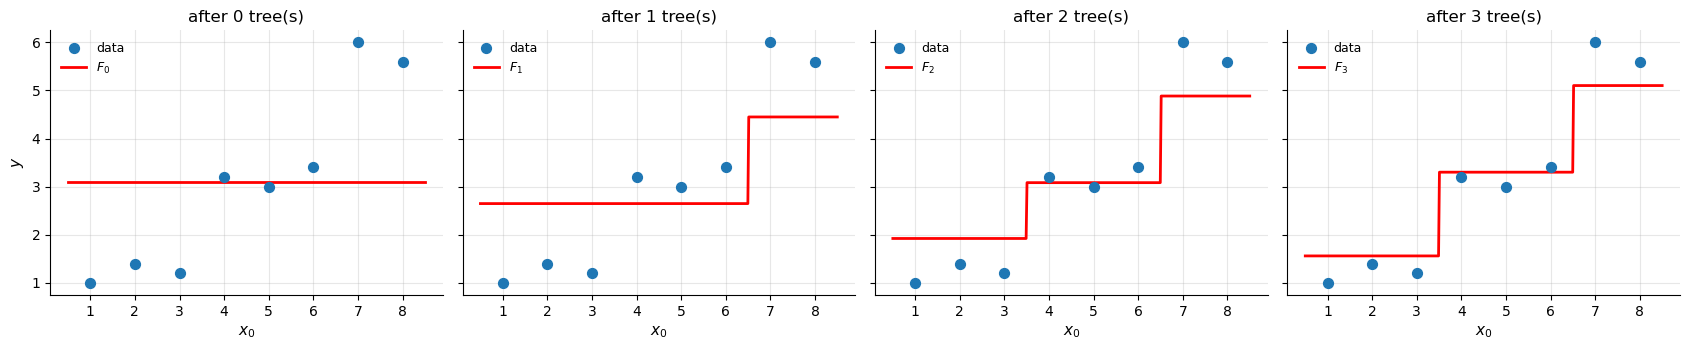

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True)
xx = np.linspace(0.5, 8.5, 400).reshape(-1, 1)
stages_toy = toy.get_staged_predictions(xx)
for k, ax in enumerate(axes):
    ax.scatter(x_toy, y_toy, color=CLASS_COLORS[0], s=50, zorder=3, label="data")
    ax.plot(xx, np.full(len(xx), toy.init_prediction_) if k == 0 else stages_toy[k - 1], "r", lw=2, label=f"$F_{k}$")
    ax.set(title=f"after {k} tree(s)", xlabel="$x_0$"); ax.legend(loc="upper left")
axes[0].set_ylabel("$y$"); plt.tight_layout(); plt.show()

Each panel adds half of one stump. The fit starts as a flat line at the mean and quickly develops the three-level staircase of the data. Each new stump's jump sits where the current residuals change sign.

## 7. Visual experiments

### 7.1 The fit after 1, 5, 20 and 200 trees

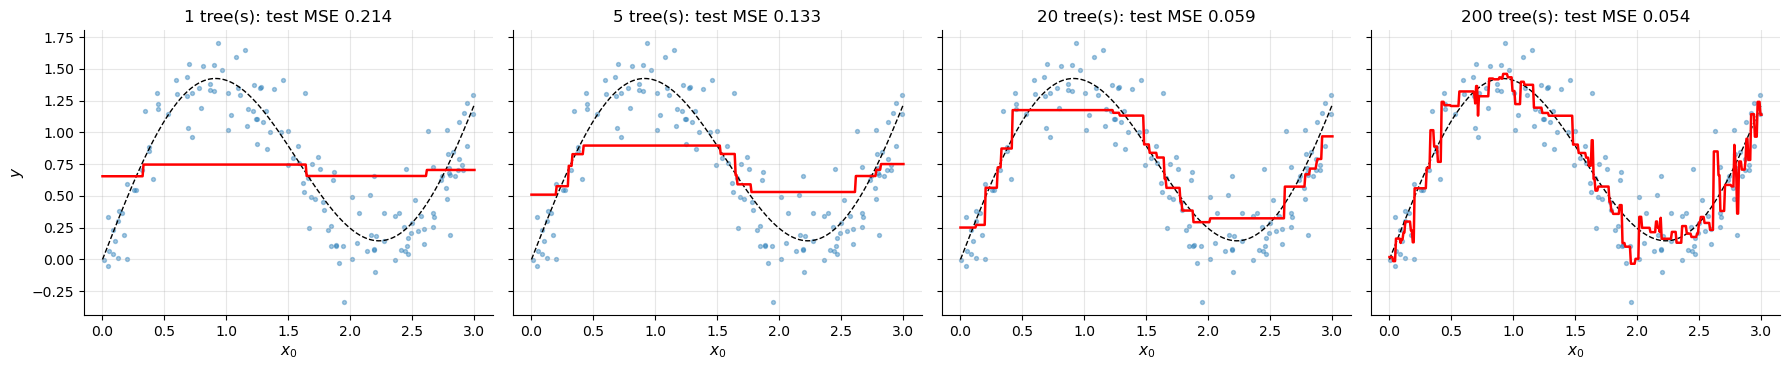

In [14]:
gb = GradientBoostingRegressor(n_estimators=200, max_depth=2, learning_rate=0.1); gb.fit(X_tr, y_tr)
stages_grid = gb.get_staged_predictions(xg)
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
for ax, T in zip(axes, [1, 5, 20, 200]):
    ax.scatter(X_tr, y_tr, s=8, alpha=0.4, color=CLASS_COLORS[0])
    ax.plot(xg, mu(xg), "k--", lw=1); ax.plot(xg, stages_grid[T - 1], "r", lw=1.8)
    test_pred = gb.get_staged_predictions(X_te)[T - 1]
    ax.set(title=f"{T} tree(s): test MSE {np.mean((test_pred - y_te) ** 2):.3f}", xlabel="$x_0$")
axes[0].set_ylabel("$y$"); plt.tight_layout(); plt.show()

With $\eta = 0.1$, one tree moves the flat start only a tenth of the way, so its fit is still almost a constant. After 5 trees the rough shape appears. After 20 trees the staircase follows the sine closely, and the test MSE has dropped most of the way toward $\sigma^2 = 0.04$. After 200 trees the test MSE is slightly lower still, but the fit has become visibly jagged: later trees are adding small corrections that track individual noisy points. Each picture is a sum of step functions, so the curve is never smooth. It becomes smoother in appearance only as many small steps accumulate.

### 7.2 Residuals shrink round by round

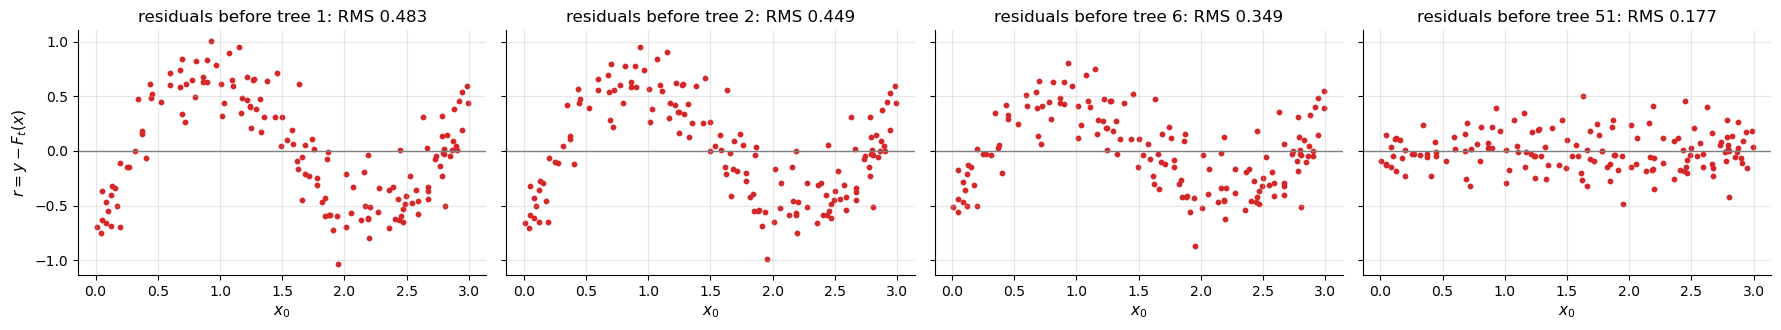

In [15]:
stages_tr = [np.full(len(y_tr), gb.init_prediction_)] + gb.get_staged_predictions(X_tr)
fig, axes = plt.subplots(1, 4, figsize=(18, 3.4), sharey=True)
for ax, t in zip(axes, [0, 1, 5, 50]):
    r = y_tr - stages_tr[t]
    ax.axhline(0, color="gray", lw=1); ax.scatter(X_tr, r, s=10, color=CLASS_COLORS[1])
    ax.set(title=f"residuals before tree {t + 1}: RMS {np.sqrt(np.mean(r ** 2)):.3f}", xlabel="$x_0$")
axes[0].set_ylabel("$r = y - F_t(x)$"); plt.tight_layout(); plt.show()

Before the first tree, the residuals are the whole signal minus its mean: a clear curve. Each round removes part of the remaining *structure*. With $\eta = 0.1$ the first tree removes only a little, so the residuals before tree 2 still look almost the same. By tree 51 the residuals look like structureless noise around zero, and their RMS has even dropped slightly *below* the noise level $\sigma = 0.2$. Below $\sigma$, the model has started to absorb some of the training noise. From this point on, new trees mostly fit noise, which is the signal to stop.

### 7.3 Learning rate and number of trees

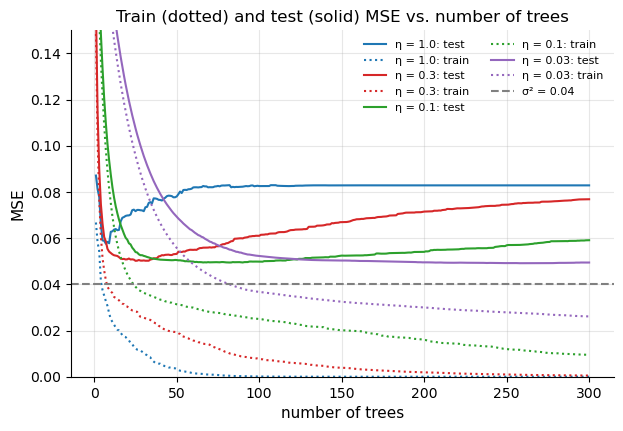

η = 1.0 : best test MSE 0.0576 at   7 trees; after 300 trees test 0.0828, train 0.0000
η = 0.3 : best test MSE 0.0502 at  25 trees; after 300 trees test 0.0768, train 0.0005
η = 0.1 : best test MSE 0.0494 at  82 trees; after 300 trees test 0.0591, train 0.0095
η = 0.03: best test MSE 0.0491 at 272 trees; after 300 trees test 0.0494, train 0.0261


In [16]:
fig, ax = plt.subplots()
lr_results = {}
for eta_, col in zip([1.0, 0.3, 0.1, 0.03], CLASS_COLORS):
    g_ = GradientBoostingRegressor(n_estimators=300, max_depth=2, learning_rate=eta_); g_.fit(X_tr, y_tr)
    tr_mse = [np.mean((p - y_tr) ** 2) for p in g_.get_staged_predictions(X_tr)]
    te_mse = [np.mean((p - y_te) ** 2) for p in g_.get_staged_predictions(X_te)]
    lr_results[eta_] = (np.min(te_mse), int(np.argmin(te_mse)) + 1, te_mse[-1], tr_mse[-1])
    ax.plot(range(1, 301), te_mse, color=col, label=f"η = {eta_}: test")
    ax.plot(range(1, 301), tr_mse, color=col, ls=":", label=f"η = {eta_}: train")
ax.axhline(SIGMA**2, color="gray", ls="--", label="σ² = 0.04")
ax.set(ylim=(0, 0.15), title="Train (dotted) and test (solid) MSE vs. number of trees", xlabel="number of trees", ylabel="MSE")
ax.legend(ncol=2, fontsize=8); plt.show()
for eta_, (best, at, last, trl) in lr_results.items():
    print(f"η = {eta_:<4}: best test MSE {best:.4f} at {at:>3} trees; after 300 trees test {last:.4f}, train {trl:.4f}")

Three regularities appear:
- **Training error always falls**, faster for larger $\eta$. With $\eta = 1$, the 300 depth-2 trees drive the training MSE essentially to zero: the model memorises the noise.
- **Every test curve falls, bottoms out, then rises** (except $\eta = 0.03$, which has not reached its minimum after 300 trees). The best number of trees scales roughly like $1/\eta$: about 7, 25, 82 and 272 trees for $\eta = 1, 0.3, 0.1, 0.03$.
- **Smaller $\eta$ gives a slightly lower minimum** and a much flatter valley around it. A small learning rate makes the result far less sensitive to the exact number of trees, which is why it is the standard advice, provided you can afford the extra trees.

### 7.4 Interactions: why tree depth matters

A sum of **stumps** is an *additive* model, $F(x) = \sum_j g_j(x_j)$. Each stump depends on a single feature, so the sum can never represent an **interaction** such as $x_0 x_1$, where the effect of one feature depends on the other. A depth-$d$ tree can express interactions among up to $d$ features. We boost on $y = 4 x_0 x_1 + \varepsilon$.

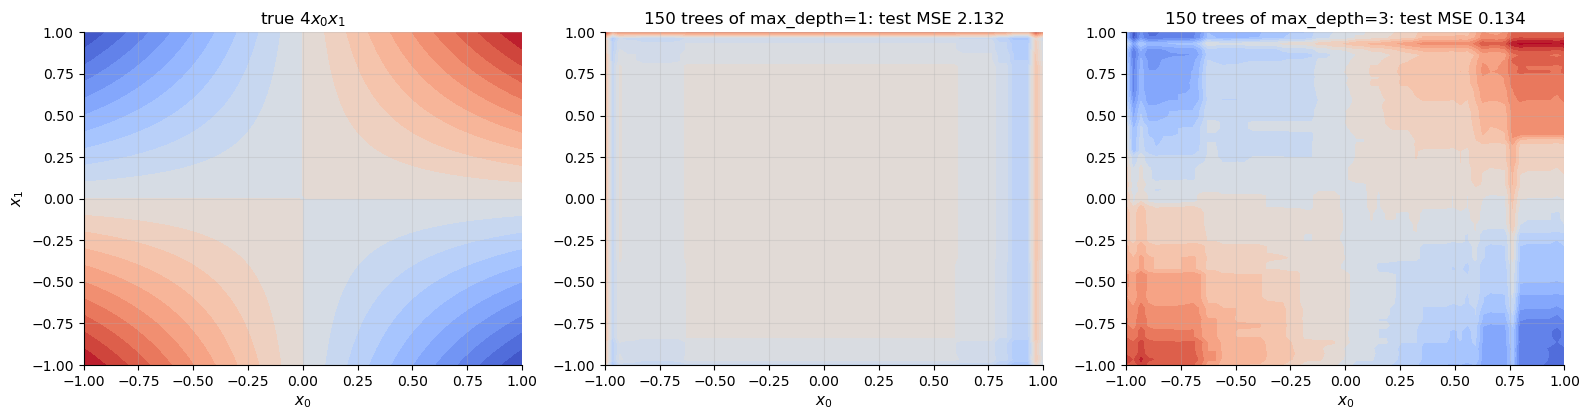

In [17]:
X2 = rng.uniform(-1, 1, size=(300, 2)); y2 = 4 * X2[:, 0] * X2[:, 1] + 0.1 * rng.normal(size=300)
X2_te = rng.uniform(-1, 1, size=(1000, 2)); y2_te = 4 * X2_te[:, 0] * X2_te[:, 1] + 0.1 * rng.normal(size=1000)
g0_, g1_ = np.meshgrid(np.linspace(-1, 1, 60), np.linspace(-1, 1, 60)); grid2 = np.c_[g0_.ravel(), g1_.ravel()]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
axes[0].contourf(g0_, g1_, 4 * g0_ * g1_, levels=20, cmap="coolwarm"); axes[0].set(title="true $4x_0x_1$", xlabel="$x_0$", ylabel="$x_1$")
for ax, depth in zip(axes[1:], [1, 3]):
    g_ = GradientBoostingRegressor(n_estimators=150, max_depth=depth, learning_rate=0.1); g_.fit(X2, y2)
    mse = np.mean((g_.predict(X2_te) - y2_te) ** 2)
    ax.contourf(g0_, g1_, g_.predict(grid2).reshape(g0_.shape), levels=20, cmap="coolwarm", vmin=-4, vmax=4)
    ax.set(title=f"150 trees of max_depth={depth}: test MSE {mse:.3f}", xlabel="$x_0$")
plt.tight_layout(); plt.show()

The true surface is a saddle: positive in two opposite quadrants and negative in the other two. Its additive part is exactly zero, because averaging $4x_0x_1$ over $x_1$ for any fixed $x_0$ gives 0. A sum of stumps therefore has nothing to fit. Its prediction is a nearly flat surface with some noise-driven stripes along the edges, and its test MSE is no better than predicting the overall mean (the variance of $4x_0x_1$ is $16/9 \approx 1.78$). Depth-3 trees can split on $x_0$ and then on $x_1$ inside each half, so they represent the quadrant structure, and the test MSE falls by more than an order of magnitude. Choose `max_depth` according to how many features you expect to interact.

### 7.5 Feature importance

`get_feature_importance(num_features)` adds up the stored `var_reduction` of every split on each feature, over all trees, and divides by the number of trees. We test it on a Friedman-style benchmark: $y = 10\sin(\pi x_0 x_1) + 20(x_2 - 0.5)^2 + 10x_3 + 5x_4 + \varepsilon$, plus a sixth, irrelevant feature $x_5$.

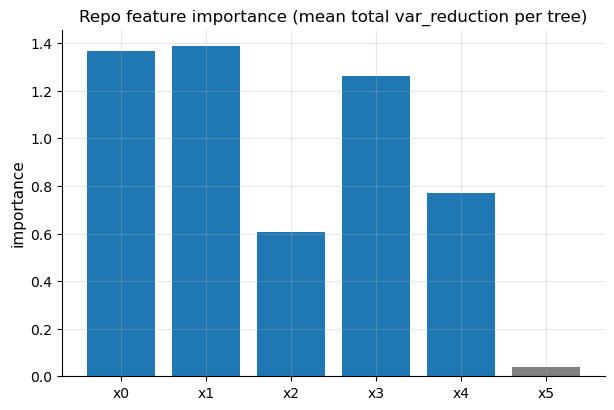

importances: [1.365 1.387 0.606 1.261 0.77  0.038] | ✓ equals the per-node sum of var_reduction / number of trees


In [18]:
X6 = rng.uniform(0, 1, size=(200, 6))
y6 = 10 * np.sin(np.pi * X6[:, 0] * X6[:, 1]) + 20 * (X6[:, 2] - 0.5) ** 2 + 10 * X6[:, 3] + 5 * X6[:, 4] + rng.normal(size=200)
g6 = GradientBoostingRegressor(n_estimators=60, max_depth=3, learning_rate=0.1); g6.fit(X6, y6)
imp = g6.get_feature_importance(6)
manual = np.zeros(6)
for t in g6.trees:
    for nd in iter_nodes(t.root):
        if nd.value is None:
            manual[nd.feature_index] += nd.var_reduction
assert np.allclose(imp, manual / len(g6.trees))
fig, ax = plt.subplots()
ax.bar([f"x{j}" for j in range(6)], imp, color=[CLASS_COLORS[0]] * 5 + ["gray"])
ax.set(title="Repo feature importance (mean total var_reduction per tree)", ylabel="importance"); plt.show()
print("importances:", np.round(imp, 3), "| ✓ equals the per-node sum of var_reduction / number of trees")

The irrelevant feature $x_5$ receives almost no importance, and all five relevant features receive substantial credit. The features with the strongest effects score highest: $x_0$ and $x_1$ through the $\sin(\pi x_0x_1)$ interaction, and $x_3$ through the large linear term. The weaker quadratic ($x_2$) and linear ($x_4$) effects score lower. The check confirms the definition used by the code.

> ⚠️ **Note on the implementation — importance is unweighted.**
> As in the [random forest](../RandomForest/RandomForest_Walkthrough.ipynb#7.4-Feature-importance), each split contributes its *per-node* variance reduction, not weighted by the fraction of samples reaching the node, and the totals are not normalised to 1. scikit-learn weights each split's impurity decrease by its node's sample count and normalises. Also note that later trees fit smaller residuals, so their splits have smaller variance reductions: the importance is dominated by the early trees.

## 8. Hyperparameters

| Hyperparameter | Controls | Guidance |
|---|---|---|
| `n_estimators` ($T$) | number of trees | Training error always falls (§4.4); test error falls, then flattens or rises. Choose $T$ with a validation set via `get_staged_predictions` (early stopping). |
| `learning_rate` ($\eta$) | shrinkage of each tree | Smaller is better but slower: roughly, halving $\eta$ needs about twice as many trees (§7.3). Must be in $(0, 2)$ for the training error to decrease; in practice $0.01$–$0.3$. |
| `max_depth` | interaction order of each tree | 1 = additive model (no interactions, §7.4); 2–6 is typical; deep trees overfit quickly. `None` = unlimited. |
| `min_samp_split` | smallest node that may be split | Regularises each tree; mostly matters for deep trees. |

**Early stopping, illustrated.** Hold out part of the training data, track the validation MSE with `get_staged_predictions`, and keep the best number of trees:

In [19]:
idx = rng.permutation(len(X_tr)); tr_idx, va_idx = idx[:110], idx[110:]
g_es = GradientBoostingRegressor(n_estimators=400, max_depth=2, learning_rate=0.1); g_es.fit(X_tr[tr_idx], y_tr[tr_idx])
val_mse = [np.mean((p - y_tr[va_idx]) ** 2) for p in g_es.get_staged_predictions(X_tr[va_idx])]
best_T = int(np.argmin(val_mse)) + 1
test_mse = [np.mean((p - y_te) ** 2) for p in g_es.get_staged_predictions(X_te)]
print(f"validation-selected T = {best_T}: test MSE {test_mse[best_T - 1]:.4f}   (all 400 trees: {test_mse[-1]:.4f}; best possible: {min(test_mse):.4f})")

validation-selected T = 29: test MSE 0.0527   (all 400 trees: 0.0711; best possible: 0.0508)


Picking $T$ on 40 held-out points recovers a test error close to the best achievable over all stopping points. This is the standard way to set `n_estimators`, and the implementation's `get_staged_predictions` makes it a few lines of code.

## 9. Complexity and limitations

**Training.** $T$ trees of depth $D$. The split search scans every midpoint of every feature with $O(n)$ mask operations, so a node costs $O(m\,n_{\text{node}}^2)$, and the model costs $O(T\,D\,m\,n^2)$. Rounds are sequential, because each tree needs the previous residuals. **Prediction.** $O(T\,D)$ per point. **Memory.** $T$ small trees.

| Limitation | Consequence | What production libraries do |
|---|---|---|
| Squared loss only | outliers get large, quadratic influence | `loss='huber'`, `'absolute_error'`, `'quantile'` |
| No row subsampling (stochastic GB) | no extra variance reduction / speed-up from subsampling | `subsample < 1` (Friedman's stochastic gradient boosting) |
| No built-in early stopping | $T$ must be chosen by the user (§8) | `validation_fraction`, `n_iter_no_change` |
| $O(m n^2)$ per node split search | `Main.py` on 20k rows is very slow | sorted sweep, or histogram binning (`HistGradientBoostingRegressor`, LightGBM, XGBoost) |
| Unweighted, unnormalised importance | biased toward early, deep splits | weighted, normalised MDI; permutation importance |
| Variance-reduction split, mean leaves | fine for squared loss; other losses need loss-aware splits and leaves | the [XGBoost notebook](../XGBoost/XGBoost_Walkthrough.ipynb) derives both from the loss |

Bugs found during this walkthrough and **fixed in the code**: the tree's `KeyError` on nodes whose features are all constant (§4.5); global `np.random.seed` calls in the booster and trees (nothing here is random); a comment claiming the leaf value is "proportional to" the mean residual, when for squared loss it is exactly the mean; 1-D/column target handling and input validation; `!= None` / `if not tree` replaced by identity tests.

## 10. Summary

- Gradient boosting fits an additive model $F_T = F_0 + \eta\sum_t f_t$ by **functional gradient descent**. It starts from $F_0 = \bar y$ (Eq. 1), and each tree approximates the negative gradient of the loss, which for squared error is the **residual** (Eq. 2).
- Each leaf holds the **mean residual** of its region, the exact line-search / Newton step for squared loss (Eq. 3). **Shrinkage** $\eta$ adds only part of each tree.
- For $0 < \eta < 2$ the training error never increases; each round lowers the SSE by $\sum_\ell |\ell|\,\bar r_\ell^2\,\eta(2-\eta)$, verified exactly against the code.
- Small $\eta$ with more trees generalises better; depth controls the **interaction order** (stumps give an additive model that cannot fit $x_0x_1$); and $T$ should be chosen by validation via `get_staged_predictions`.
- The implementation's tree uses midpoint thresholds and vectorised splits. Fixed during this walkthrough: the constant-feature `KeyError`, global seeding, a misleading comment, and input handling.

**Next:** the same machinery with log-loss, softmax and genuine Newton steps: [Gradient Boosting for classification](../GradientBoostClassification/GradientBoostClassification_Walkthrough.ipynb).